# Building a Basic Chatbot with LangGraph

In [1]:
# Annotated lets us attach an extra rule to a type (we use it for the chat history below)
from typing import Annotated
# TypedDict lets us describe a dictionary with fixed, named slots
from typing import TypedDict
# StateGraph builds the bot's flowchart; START and END mark where the flow begins and stops
from langgraph.graph import StateGraph, START, END
# add_messages makes new messages get ADDED to the chat history instead of replacing it
from langgraph.graph.message import  add_messages #reducer

## State Declaration

In [2]:
# The State is the bot's notepad: everything it keeps track of while it runs
class State(TypedDict):
    # A list holding the whole conversation; add_messages keeps adding new messages to the end
    messages: Annotated[list, add_messages]

## Loading the Environment Variables

In [3]:
# os lets Python read settings from your computer, like your API keys
import os
# load_dotenv can read the secret keys stored in your .env file
from dotenv import load_dotenv
# Load the keys from .env so the code can use them (shows True if it found the file)
load_dotenv()

True

In [4]:
# A helper that can create chat models from many AI companies (imported, but not used below)
from langchain.chat_models import init_chat_model

In [5]:
# The connector that lets us talk to Google's Gemini AI
from langchain_google_genai import ChatGoogleGenerativeAI

## Initializing the LLM

In [6]:
# gemini-flash-lite-latest: same model as notebooks 2-5, and it works on the free Gemini API tier.
# Create the AI model: the "brain" that reads messages and writes replies
llm = ChatGoogleGenerativeAI(
    # Which Gemini model to use
    model = "gemini-flash-lite-latest",
    # 0 means no creativity/randomness: the same question gives (almost) the same answer
    temperature = 0
)

ValidationError: 1 validation error for ChatGoogleGenerativeAI
  Value error, API key required for Gemini Developer API. Provide api_key parameter or set GOOGLE_API_KEY/GEMINI_API_KEY environment variable. [type=value_error, input_value={'model': 'gemini-flash-l...': {}, 'base_url': None}, input_type=dict]
    For further information visit https://errors.pydantic.dev/2.14/v/value_error

## Chatbot function for node

In [7]:
# The chatbot step: hand the conversation so far to the AI
def chatbot(state: State):
    # Ask the AI for a reply and add that reply to the conversation
    return {"messages": [llm.invoke(state["messages"])]}

## Creating an instance of Graph Builder Class

In [8]:
# Start an empty flowchart that uses our State as its notepad
graph_builder = StateGraph(State)

Initializing nodes and adding edges to graph

In [9]:
# Add a box called "Chatbot" that runs the chatbot function
graph_builder.add_node("Chatbot", chatbot)

# Arrow: when the bot starts, go to the Chatbot box first
graph_builder.add_edge(START, "Chatbot")
# Arrow: after the Chatbot box, stop
graph_builder.add_edge("Chatbot", END)

# Finish the flowchart and turn it into something we can run
graph = graph_builder.compile()

Visual of graph workflow

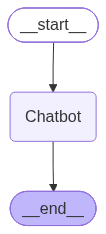

In [10]:
# Show a picture of the flowchart
graph

In [11]:
# Offline text version of the graph (the picture above is rendered by a remote service).
# Paste the output into https://mermaid.live if you want to see it drawn.
# Print the flowchart as text instead of a picture
print(graph.get_graph().draw_mermaid())


---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	Chatbot(Chatbot)
	__end__([<p>__end__</p>]):::last
	__start__ --> Chatbot;
	Chatbot --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



## Testing the Graph

In [12]:
# Run the bot with the message "hELLO wORLD!" and show everything it returns
graph.invoke({"messages": "hELLO wORLD!"})

{'messages': [HumanMessage(content='hELLO wORLD!', additional_kwargs={}, response_metadata={}, id='d60e8fc9-a463-417b-b11d-83c4c65a8ca6'),
  AIMessage(content=[{'type': 'text', 'text': 'Hello World! How can I help you today?', 'extras': {'signature': 'EmAKXgFpFH0TP9PJG9VEKiDWHPxAe88VZoB/uo4dJtU6RREPrI2R4nyAdYUhSnwkX9gG2+wS3eIF5njhpp5pbzJ6IFnKbnvybaI8ekA3IeYpT14kRd2VwTOUN4G/0vGh3yQ='}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a17ce1-15c5-7526-9b6b-5de774d40261-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 8, 'output_tokens': 10, 'total_tokens': 18, 'input_token_details': {'cache_read': 0}})]}

In [13]:
# Ask the bot a question and save its full answer in "response"
response = graph.invoke({'messages': "What do you think about garfield the cat?"})

In [14]:
# Show the full answer
print(response)

{'messages': [HumanMessage(content='What do you think about garfield the cat?', additional_kwargs={}, response_metadata={}, id='fa2fb7e5-c89d-4295-b1a8-602e55843fa1'), AIMessage(content=[{'type': 'text', 'text': 'Ah, Garfield! He’s an absolute icon of pop culture and the patron saint of lazy people everywhere. \n\nHere is my breakdown of the famous orange feline:\n\n*   **The Relatability Factor:** Let’s be honest—we all have a little bit of Garfield in us. Who *doesn\'t* hate Mondays, love sleeping in, and view diet plans as a personal insult? Jim Davis tapped into a universal human truth: sometimes you just want to lie on the couch and eat carbs.\n*   **The Brand of Humor:** Garfield\'s humor is delightfully cynical and deadpan. He’s sarcastic, he terrorizes the dog (Odin... I mean Odie), and he endlessly torments his owner, Jon Arbuckle. It’s simple, comforting, Sunday-funnies humor.\n*   **The Cultural Phenomenon:** You can\'t talk about Garfield without acknowledging the sheer sca